> **Version corrigée, à ne pas distribuer.** Les exercices sont résolus et les réponses rédigées ; les sorties ont été produites par l'exécution complète du notebook.

# TP Python — Perceptrons et réseaux de neurones : les implémenter

*Séance en salle informatique : on programme des perceptrons et des réseaux de neurones, et on vérifie les programmes sur des exemples calculés à la main.*

**Au programme**
1. les fonctions d'activation et le perceptron ;
2. la règle d'apprentissage du perceptron, et son échec sur le XOR ;
3. des réseaux à plusieurs couches, construits « à la main » ;
4. pourquoi il faudra remplacer la fonction de Heaviside, ce qui prépare le TP [TP Python : rétropropagation et méthodes d'apprentissage](https://openyourmath.org/exercise/bNCl) (`bNCl`).

**Conventions** (celles du poly d'OPTRN)
- $H(t)=1$ si $t\geq 0$ et $H(t)=0$ sinon : **$H(0)=1$**.
- Un exemple est une **colonne** : un lot de $m$ exemples à $n$ entrées est un tableau `X` de forme `(n, m)`.
- Une couche de $n$ neurones recevant $p$ entrées a une matrice de poids `W` de forme `(n, p)` et un vecteur de biais `b` de taille `n` : sa sortie est `activation(W @ A + b)`, comme dans l'exercice [Modélisation : de la somme scalaire au produit matriciel](https://openyourmath.org/exercise/UUNO) (`UUNO`).

**Comment travailler.** Les cellules marquées `À COMPLÉTER` sont à écrire. La cellule de test qui suit (des `assert`) vous dit tout de suite si c'est correct ; plusieurs tests reprennent les résultats d'exercices à calculer à la main, cités à chaque fois. Ne passez pas à la suite tant qu'un test échoue.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (5, 4)

## 1. Fonctions d'activation

La sigmoïde $\sigma(z)=\dfrac{1}{1+e^{-z}}$ est fournie, écrite pour ne pas déborder quand $z$ est très négatif. Écrivez `heaviside` et `relu`.

In [2]:
def sigmoide(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

In [3]:
def heaviside(z):
    """H(z) = 1 si z >= 0, 0 sinon (attention : H(0) = 1)."""
    return np.where(np.asarray(z) >= 0, 1.0, 0.0)


def relu(z):
    """ReLU(z) = max(0, z)."""
    return np.maximum(0, z)

In [4]:
# Test
assert heaviside(0) == 1, "H(0) doit valoir 1"
assert heaviside(-0.001) == 0 and heaviside(2) == 1
assert np.array_equal(heaviside(np.array([-1.0, 0.0, 3.0])), [0, 1, 1]), "heaviside doit marcher sur un tableau"
assert np.array_equal(relu(np.array([-2.0, 0.0, 3.0])), [0, 0, 3])
assert np.isclose(sigmoide(0), 0.5)
print("Activations : OK")

Activations : OK


## 2. Le perceptron

Un perceptron à $n$ entrées de poids $w\in\mathbb R^n$ et de biais $b$ calcule $F(x)=\phi(w\cdot x+b)$.
Écrivez `perceptron(X, w, b, activation)` : `X` est un tableau `(n, m)`, `w` un tableau de taille `n`, `b` un nombre, et la fonction renvoie les `m` sorties.

In [5]:
def perceptron(X, w, b, activation=heaviside):
    """X : (n, m), w : (n,), b : nombre -> tableau (m,) des sorties."""
    return activation(w @ X + b)

**Test : exercices à calculer à la main.** Les valeurs attendues sont celles des exercices [Évaluer un perceptron à deux entrées, avec ou sans biais](https://openyourmath.org/exercise/XDVP) (`XDVP`), [Une couleur est-elle une nuance de rouge ?](https://openyourmath.org/exercise/u8jz) (`u8jz`) et [Score d'un perceptron sigmoïde : taille et poids](https://openyourmath.org/exercise/Pde0) (`Pde0`).

In [6]:
# Exercice XDVP (https://openyourmath.org/exercise/XDVP) : F(x, y) = H(3x - 2y), puis avec le biais -3
X_td = np.array([[2, -1, 2, 0, -4],
                 [1,  2, 3, -1, -5]], dtype=float)
w_td = np.array([3.0, -2.0])
assert np.array_equal(perceptron(X_td, w_td, 0.0), [1, 0, 1, 1, 0]), "sans biais"
assert np.array_equal(perceptron(X_td, w_td, -3.0), [1, 0, 0, 0, 0]), "avec le biais -3"

# Exercice u8jz (https://openyourmath.org/exercise/u8jz) : la couleur (r, g, b) est-elle une nuance de rouge ?
couleurs = np.array([[1.0, 0.0, 0.0], [0.9, 0.1, 0.1], [0.5, 0.2, 0.1],
                     [0.0, 1.0, 0.0], [0.5, 0.0, 0.0]]).T
assert np.array_equal(perceptron(couleurs, np.array([2.0, -2.0, -2.0]), -1.0), [1, 1, 0, 0, 1])

# Exercice Pde0 (https://openyourmath.org/exercise/Pde0) : score sigmoïde (taille en m, poids en kg)
personnes = np.array([[1.70, 66], [1.72, 72], [1.80, 76]]).T
scores = perceptron(personnes, np.array([85.0, -1.0]), -77.0, sigmoide)
assert np.allclose(scores, [0.82, 0.06, 0.5], atol=0.005), scores
print("Perceptron : OK")

Perceptron : OK


### Voir la frontière

La fonction `tracer_region` (fournie) colorie le plan selon la sortie d'une fonction `f` qui prend un tableau `(2, m)` de points.
Tracez, côte à côte, la sortie du perceptron $F(x,y)=H(3x-2y+b)$ pour $b=0$ puis $b=-3$ sur $[-5,5]^2$, avec les cinq points de l'exercice [Évaluer un perceptron à deux entrées, avec ou sans biais](https://openyourmath.org/exercise/XDVP) (`XDVP`).

In [7]:
def grille(xlim, ylim, n=300):
    xs = np.linspace(xlim[0], xlim[1], n)
    ys = np.linspace(ylim[0], ylim[1], n)
    XX, YY = np.meshgrid(xs, ys)
    return XX, YY, np.vstack([XX.ravel(), YY.ravel()])


def tracer_region(f, xlim=(-3, 3), ylim=(-3, 3), ax=None, points=None, etiquettes=None, titre=""):
    """Colorie le plan selon f : (2, m) -> (m,). Place aussi des points (2, k)."""
    ax = ax if ax is not None else plt.gca()
    XX, YY, G = grille(xlim, ylim)
    Z = np.asarray(f(G)).reshape(XX.shape)
    ax.contourf(XX, YY, Z, levels=np.linspace(-0.001, 1.001, 12), cmap="Blues", vmin=0, vmax=1, alpha=0.5)
    if points is not None:
        if etiquettes is None:
            couleurs = "k"
        else:
            couleurs = np.where(np.asarray(etiquettes) >= 0.5, "tab:blue", "tab:red")
        ax.scatter(points[0], points[1], c=couleurs, edgecolor="k", zorder=3)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect("equal")
    ax.set_title(titre)
    ax.grid(alpha=0.3)

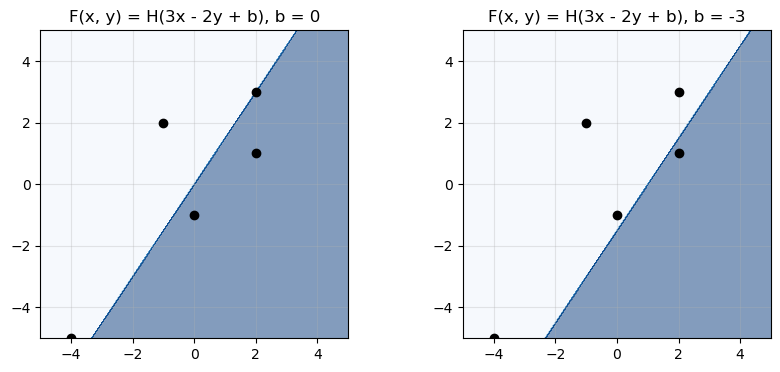

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, b in zip(axes, (0.0, -3.0)):
    tracer_region(lambda G: perceptron(G, w_td, b), xlim=(-5, 5), ylim=(-5, 5),
                  ax=ax, points=X_td, titre=f"F(x, y) = H(3x - 2y + b), b = {b:g}")
plt.show()

**Question.** Où passe la frontière du premier perceptron ? Du second ? Que fait le biais ?

**Réponse.** La frontière du premier perceptron est la droite $3x-2y=0$, qui passe par l'origine ; celle du second est la droite $3x-2y-3=0$, parallèle à la première mais décalée (elle passe par $(1,0)$). Le biais déplace la frontière sans changer sa direction : sans biais, un perceptron ne peut séparer que par des droites passant par l'origine. La sortie vaut 1 sur la droite elle-même, puisque $H(0)=1$.

## 3. Apprendre un perceptron

Jusqu'ici, c'est vous qui avez choisi les poids. La **règle d'apprentissage du perceptron** les trouve à partir d'exemples $(x_i, t_i)$ avec $t_i\in\{0,1\}$ :
pour chaque exemple, on calcule la sortie $y_i=F(x_i)$ puis
$$w \leftarrow w+\eta\,(t_i-y_i)\,x_i,\qquad b\leftarrow b+\eta\,(t_i-y_i).$$
Si l'exemple est bien classé, $t_i-y_i=0$ et rien ne bouge ; sinon la frontière est déplacée vers la bonne classe. On repasse sur tous les exemples (une *époque*) jusqu'à ne plus faire d'erreur.

Écrivez la fonction `apprendre_perceptron`. Elle renvoie les poids finaux, le nombre d'erreurs à la fin de chaque époque, et l'historique des poids **après chaque correction** (c'est-à-dire chaque fois qu'un exemple était mal classé).

In [9]:
def donnees_separables(m=40, graine=0, marge=0.2):
    """m points du plan, étiquetés selon une droite cachée, avec une marge étroite autour d'elle."""
    rng = np.random.default_rng(graine)
    X = rng.uniform(-3, 3, size=(2, 20 * m))
    s = X[0] - 0.7 * X[1] + 0.3
    X = X[:, np.abs(s) > marge][:, :m]
    t = (X[0] - 0.7 * X[1] + 0.3 > 0).astype(float)
    return X, t

In [10]:
def apprendre_perceptron(X, t, eta=0.1, epoques=100):
    """Règle d'apprentissage du perceptron.

    Renvoie w, b, erreurs, historique :
    - erreurs[k] : nombre d'exemples mal classés à la fin de l'époque k ;
    - historique : liste des (w, b), au départ puis après chaque correction.
    """
    n, m = X.shape
    w = np.zeros(n)
    b = 0.0
    historique = [(w.copy(), b)]
    erreurs = []
    for _ in range(epoques):
        for i in range(m):
            y = heaviside(w @ X[:, i] + b)
            w = w + eta * (t[i] - y) * X[:, i]
            b = b + eta * (t[i] - y)
            if y != t[i]:
                historique.append((w.copy(), b))   # on mémorise la frontière après chaque correction
        erreurs.append(int(np.sum(perceptron(X, w, b) != t)))
        if erreurs[-1] == 0:
            break
    return w, b, erreurs, historique

In [11]:
# Test
X_sep, t_sep = donnees_separables()
w, b, erreurs, historique = apprendre_perceptron(X_sep, t_sep)
assert erreurs[-1] == 0, "le perceptron doit finir par classer correctement des points séparables"
assert len(erreurs) < 100
print(f"Convergence en {len(erreurs)} époques et {len(historique) - 1} corrections, w = {w.round(2)}, b = {b:.2f}")

Convergence en 5 époques et 14 corrections, w = [ 0.61 -0.33], b = 0.00


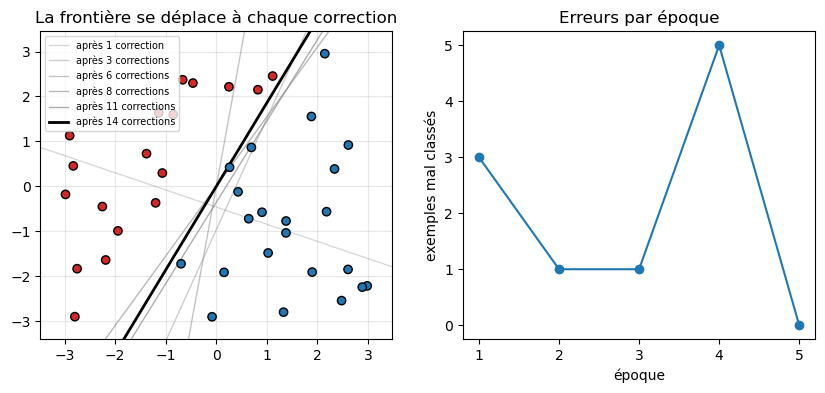

In [12]:
def tracer_droite(ax, w, b, xlim, **kw):
    xs = np.array(xlim)
    if abs(w[1]) > 1e-12:
        ax.plot(xs, -(w[0] * xs + b) / w[1], **kw)
    elif abs(w[0]) > 1e-12:
        ax.axvline(-b / w[0], **kw)


def tracer_historique(X, t, historique, ax=None, nb=6):
    ax = ax if ax is not None else plt.gca()
    ax.scatter(X[0], X[1], c=np.where(t >= 0.5, "tab:blue", "tab:red"), edgecolor="k", zorder=3)
    xlim = (X[0].min() - 0.5, X[0].max() + 0.5)
    indices = np.unique(np.linspace(1, len(historique) - 1, nb).astype(int))
    for rang, k in enumerate(indices):
        w_k, b_k = historique[k]
        fin = rang == len(indices) - 1
        tracer_droite(ax, w_k, b_k, xlim, color="k" if fin else "gray", lw=2 if fin else 1,
                      alpha=1 if fin else 0.3 + 0.5 * rang / len(indices), label=f"après {k} correction" + ("s" if k > 1 else ""))
    ax.set_xlim(xlim)
    ax.set_ylim(X[1].min() - 0.5, X[1].max() + 0.5)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
tracer_historique(X_sep, t_sep, historique, ax=axes[0])
axes[0].set_title("La frontière se déplace à chaque correction")
axes[1].plot(range(1, len(erreurs) + 1), erreurs, "o-")
axes[1].set_xlabel("époque")
axes[1].set_ylabel("exemples mal classés")
axes[1].set_title("Erreurs par époque")
plt.show()

### Et pour le XOR ?

On donne au même algorithme les quatre points du XOR (étiquette 1 pour $(1,0)$ et $(0,1)$, 0 pour $(0,0)$ et $(1,1)$) et 100 époques.

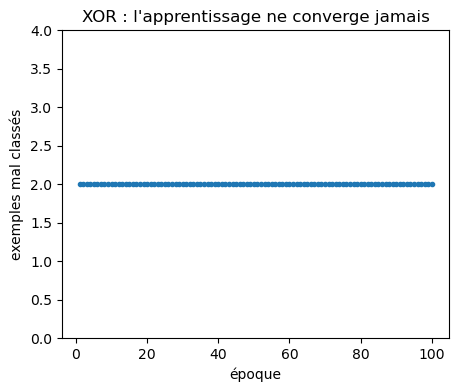

In [13]:
X_xor = np.array([[0, 1, 0, 1],
                  [0, 0, 1, 1]], dtype=float)
t_xor = np.array([0, 1, 1, 0], dtype=float)

_, _, erreurs_xor, _ = apprendre_perceptron(X_xor, t_xor, eta=0.1, epoques=100)
assert len(erreurs_xor) == 100 and min(erreurs_xor) >= 1, "le perceptron ne doit jamais atteindre 0 erreur sur le XOR"
plt.plot(range(1, 101), erreurs_xor, ".-")
plt.xlabel("époque")
plt.ylabel("exemples mal classés")
plt.title("XOR : l'apprentissage ne converge jamais")
plt.ylim(0, 4)
plt.show()

**Question.** Pourquoi cela ne peut-il pas converger ? (Reprenez l'argument du milieu du segment de l'exercice [Pourquoi plusieurs couches ? Le problème XOR](https://openyourmath.org/exercise/KmBY) (`KmBY`).)

**Réponse.** Supposons qu'un perceptron classe correctement les quatre points, avec $s(x,y)=ax+by+c$ affine et la règle « sortie 1 si $s\geq 0$ ». Le point $(1/2,1/2)$ est le milieu de $(1,0)$ et $(0,1)$ ; comme $s$ est affine, $s(1/2,1/2)$ est la moyenne de deux nombres positifs ou nuls, donc $s(1/2,1/2)\geq 0$. Mais c'est aussi le milieu de $(0,0)$ et $(1,1)$, où $s<0$, donc $s(1/2,1/2)<0$. Contradiction : aucun réglage des poids ne convient, et l'algorithme tourne indéfiniment.

## 4. Des perceptrons aux réseaux

Un réseau est une suite de couches. Écrivez
- `dense(A, W, b, activation)` : la sortie d'**une** couche, avec `A` de forme `(p, m)`, `W` de forme `(n, p)`, `b` de taille `n` ;
- `reseau(X, couches)` : la propagation à travers une liste de couches `(W, b, activation)`.

Pensez au biais : il faut l'ajouter à **chaque colonne** de `W @ A`.

In [14]:
def dense(A, W, b, activation):
    """A : (p, m), W : (n, p), b : (n,) -> (n, m)."""
    return activation(W @ A + b[:, None])


def reseau(X, couches):
    """couches : liste de (W, b, activation). Renvoie la sortie du réseau."""
    A = X
    for W, b, activation in couches:
        A = dense(A, W, b, activation)
    return A

**Test : le réseau du XOR** (exercice [Pourquoi plusieurs couches ? Le problème XOR](https://openyourmath.org/exercise/KmBY) (`KmBY`)) : $h_1=H(x-y-\tfrac12)$, $h_2=H(y-x-\tfrac12)$ puis $F=H(h_1+h_2-\tfrac12)$.

In [15]:
couches_xor = [
    (np.array([[1.0, -1.0], [-1.0, 1.0]]), np.array([-0.5, -0.5]), heaviside),
    (np.array([[1.0, 1.0]]), np.array([-0.5]), heaviside),
]
sortie = reseau(X_xor, couches_xor)
assert sortie.shape == (1, 4), f"forme attendue (1, 4), obtenue {sortie.shape}"
assert np.array_equal(sortie[0], [0, 1, 1, 0])
print("Réseau XOR : OK")

Réseau XOR : OK


### Construire des réseaux

À vous de trouver les poids. Dans les deux cas, la première couche calcule des demi-plans et la seconde les combine par un « ET » (un neurone dont le biais est $-k$ pour $k$ entrées à 1).

1. **La bande** $\{(x,y)\mid |x-y|\leq 1\}$ (exercice [Reconnaître une bande du plan](https://openyourmath.org/exercise/VLwo) (`VLwo`)) : deux demi-plans.
2. **Le triangle** de sommets $(-1,-1)$, $(-1,1)$, $(1,1)$ (exercice [Classification des points d'un triangle](https://openyourmath.org/exercise/djCi) (`djCi`)) : trois demi-plans.

Écrivez les inégalités sur papier d'abord, puis les matrices.

In [16]:
# La bande |x - y| <= 1 : 1 - x + y >= 0 et 1 + x - y >= 0
W1_bande = np.array([[-1.0, 1.0], [1.0, -1.0]])
b1_bande = np.array([1.0, 1.0])
W2_bande = np.array([[1.0, 1.0]])
b2_bande = np.array([-1.5])

# Le triangle de sommets (-1, -1), (-1, 1), (1, 1) : x >= -1, y <= 1 et y >= x
W1_tri = np.array([[1.0, 0.0], [0.0, -1.0], [-1.0, 1.0]])
b1_tri = np.array([1.0, 1.0, 0.0])
W2_tri = np.array([[1.0, 1.0, 1.0]])
b2_tri = np.array([-3.0])

Bande et triangle : OK


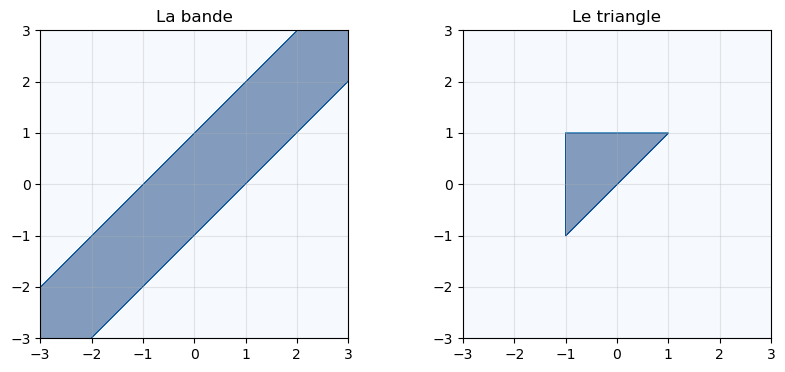

In [17]:
# Test
assert W1_bande is not None and W1_tri is not None, "complétez les poids"
reseau_bande = [(W1_bande, b1_bande, heaviside), (W2_bande, b2_bande, heaviside)]
reseau_tri = [(W1_tri, b1_tri, heaviside), (W2_tri, b2_tri, heaviside)]

# Les quatre points de l'exercice VLwo (https://openyourmath.org/exercise/VLwo) sur la bande
pts = np.array([[0.0, 1.0, 2.0, 0.0], [0.0, 0.0, 0.0, 2.0]])
assert np.array_equal(reseau(pts, reseau_bande)[0], [1, 1, 0, 0]), "bande : (0,0), (1,0), (2,0), (0,2)"

# Comparaison avec la définition géométrique sur 2000 points au hasard
G = np.random.default_rng(0).uniform(-3, 3, size=(2, 2000))
attendu_bande = np.abs(G[0] - G[1]) <= 1
attendu_tri = (G[0] >= -1) & (G[1] <= 1) & (G[1] >= G[0])
assert np.array_equal(reseau(G, reseau_bande)[0], attendu_bande), "la bande n'est pas reconnue exactement"
assert np.array_equal(reseau(G, reseau_tri)[0], attendu_tri), "le triangle n'est pas reconnu exactement"
print("Bande et triangle : OK")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
tracer_region(lambda G: reseau(G, reseau_bande)[0], ax=axes[0], titre="La bande")
tracer_region(lambda G: reseau(G, reseau_tri)[0], ax=axes[1], titre="Le triangle")
plt.show()

### Lire un réseau

Le réseau suivant est celui de l'exercice [Réseau de neurones multicouches](https://openyourmath.org/exercise/653s) (`653s`). Trois neurones de Heaviside en première couche, un neurone de Heaviside en sortie.
**Avant de tracer**, déterminez à la main la région reconnue : écrivez les trois inégalités, puis calculez les sommets du triangle qu'elles délimitent.

In [18]:
couches_653 = [
    (np.array([[-1.0, 2.0], [1.0, 1.0], [0.0, -1.0]]), np.array([0.0, -2.0, 3.0]), heaviside),
    (np.array([[1.0, 1.0, 1.0]]), np.array([-3.0]), heaviside),
]

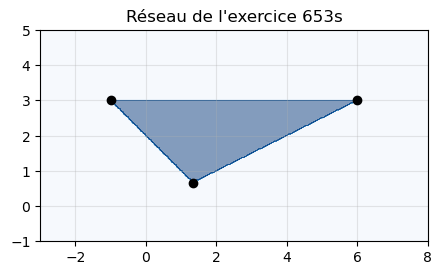

In [19]:
# Inégalités : -x + 2y >= 0, x + y - 2 >= 0, 3 - y >= 0. Sommets :
#   -x + 2y = 0 et x + y = 2  ->  (4/3, 2/3)
#   -x + 2y = 0 et y = 3      ->  (6, 3)
#   x + y = 2 et y = 3        ->  (-1, 3)
sommets = np.array([[4 / 3, 6.0, -1.0],
                    [2 / 3, 3.0, 3.0]])

tracer_region(lambda G: reseau(G, couches_653)[0], xlim=(-3, 8), ylim=(-1, 5), points=sommets,
              titre="Réseau de l'exercice 653s")
plt.show()

In [20]:
# Test : un peu à l'intérieur des sommets, la sortie vaut 1 ; un peu à l'extérieur, elle vaut 0
assert sommets is not None, "calculez les sommets"
centre = sommets.mean(axis=1, keepdims=True)
dedans = centre + 0.99 * (sommets - centre)
dehors = centre + 1.01 * (sommets - centre)
assert np.array_equal(reseau(dedans, couches_653)[0], [1, 1, 1]), "les sommets ne sont pas ceux du triangle"
assert np.array_equal(reseau(dehors, couches_653)[0], [0, 0, 0]), "les sommets ne sont pas ceux du triangle"
print("Sommets : OK")

Sommets : OK


## 5. Pourquoi il faut changer d'activation

On voudrait *apprendre* les poids d'un réseau comme on a appris ceux d'un perceptron, mais en faisant de la **descente de gradient** : il faut donc dériver la sortie par rapport aux poids, donc dériver les fonctions d'activation.

Écrivez `derivee_numerique(f, z, h)`, qui approche $f'(z)$ par $\dfrac{f(z+h)-f(z-h)}{2h}$, et comparez Heaviside et sigmoïde.

In [21]:
def derivee_numerique(f, z, h=1e-6):
    return (f(z + h) - f(z - h)) / (2 * h)

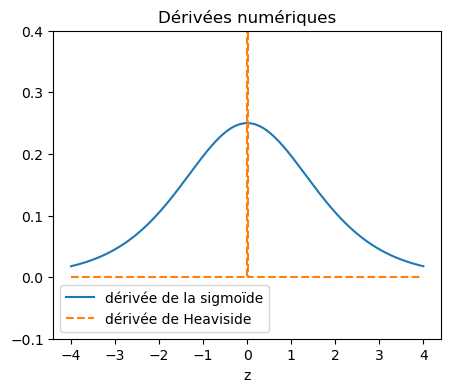

Dérivée de Heaviside en 0 : 500000.0


In [22]:
# Test
z0 = 0.7
attendu = sigmoide(z0) * (1 - sigmoide(z0))
assert np.isclose(derivee_numerique(sigmoide, z0), attendu, rtol=1e-6), "σ'(z) = σ(z)(1 - σ(z))"
assert derivee_numerique(heaviside, z0) == 0

z = np.linspace(-4, 4, 801)
plt.plot(z, derivee_numerique(sigmoide, z), label="dérivée de la sigmoïde")
plt.plot(z, derivee_numerique(heaviside, z), "--", label="dérivée de Heaviside")
plt.ylim(-0.1, 0.4)
plt.legend()
plt.xlabel("z")
plt.title("Dérivées numériques")
plt.show()
print("Dérivée de Heaviside en 0 :", derivee_numerique(heaviside, 0.0))

**Question.** Que vaut la dérivée de Heaviside en dehors de 0 ? Pourquoi cela empêche-t-il d'entraîner un réseau de Heaviside par descente de gradient ?

**Réponse.** En dehors de 0, la dérivée de Heaviside est nulle (la fonction est constante par morceaux) ; en 0 elle n'existe pas, et la dérivée numérique y donne une valeur gigantesque ($1/2h$) qui ne signifie rien. Un gradient presque partout nul ne dit pas comment modifier les poids pour réduire l'erreur : la descente de gradient ne bouge pas. On remplace donc Heaviside par une fonction dérivable (la **sigmoïde**) ou dérivable presque partout avec une pente utile (**ReLU**) : c'est ce que fait le TP [TP Python : rétropropagation et méthodes d'apprentissage](https://openyourmath.org/exercise/bNCl) (`bNCl`).

## Fiche de résultats

Cette cellule recalcule les valeurs demandées dans l'exercice [TP Python : programmer perceptrons et réseaux](https://openyourmath.org/exercise/96ip) (`96ip`) (questions 1, 3, 4 et 6). Elle ne fonctionne que si **toutes** les cellules précédentes sont complétées et correctes. Recopiez ce qu'elle affiche : toutes les graines sont fixées, vos résultats doivent être exactement ceux attendus.

In [23]:
# Fiche de résultats
RESULTATS = {}

X_sep, t_sep = donnees_separables()
w_f, b_f, err_f, hist_f = apprendre_perceptron(X_sep, t_sep)
RESULTATS["q1"] = {"epoques": len(err_f), "corrections": len(hist_f) - 1, "w": [round(float(v), 2) for v in w_f]}
print(f"Q1. Règle d'apprentissage : {len(err_f)} époques, {len(hist_f) - 1} corrections, w = {np.round(w_f, 2)}")

_, _, err_xor_f, _ = apprendre_perceptron(X_xor, t_xor, eta=0.1, epoques=100)
RESULTATS["q3"] = sorted(set(err_xor_f))
print(f"Q3. XOR : valeurs prises par le nombre d'exemples mal classés : {sorted(set(err_xor_f))}")

G_f = np.random.default_rng(0).uniform(-3, 3, size=(2, 2000))
n_bande = int(reseau(G_f, reseau_bande)[0].sum())
n_tri = int(reseau(G_f, reseau_tri)[0].sum())
RESULTATS["q4"] = {"bande": n_bande, "triangle": n_tri}
print(f"Q4. Sur 2000 points tirés au hasard dans [-3, 3]² : {n_bande} dans la bande, {n_tri} dans le triangle")

h6 = derivee_numerique(heaviside, 0.0, 1e-6)
h4 = derivee_numerique(heaviside, 0.0, 1e-4)
RESULTATS["q6"] = {"h1e-6": float(h6), "h1e-4": float(h4)}
print(f"Q6. Dérivée numérique de Heaviside en 0 : {h6:g} pour h = 1e-6, {h4:g} pour h = 1e-4")

Q1. Règle d'apprentissage : 5 époques, 14 corrections, w = [ 0.61 -0.33]
Q3. XOR : valeurs prises par le nombre d'exemples mal classés : [2]
Q4. Sur 2000 points tirés au hasard dans [-3, 3]² : 622 dans la bande, 109 dans le triangle
Q6. Dérivée numérique de Heaviside en 0 : 500000 pour h = 1e-6, 5000 pour h = 1e-4


### Réponses aux questions d'expérimentation de l'exercice associé

In [24]:
# Question 2 : nombre de corrections pour les graines 0 à 5, avec eta = 0,1 puis eta = 1
for eta in (0.1, 1.0):
    nb = []
    for graine in range(6):
        Xg, tg = donnees_separables(graine=graine)
        _, _, e, h = apprendre_perceptron(Xg, tg, eta=eta)
        nb.append(len(h) - 1)
    RESULTATS[f"q2_eta{eta}"] = nb
    print(f"Q2. corrections pour les graines 0 à 5 (eta = {eta}) : {nb}")

# Question 5 : la bande |x - y| <= 2 : seul b1 change, de (1, 1) à (2, 2)
b1_large = np.array([2.0, 2.0])
reseau_large = [(W1_bande, b1_large, heaviside), (W2_bande, b2_bande, heaviside)]
assert np.array_equal(reseau(G_f, reseau_large)[0], np.abs(G_f[0] - G_f[1]) <= 2)
RESULTATS["q5"] = {"b1": [2.0, 2.0]}
print("Q5. b1 = (2, 2), les autres paramètres inchangés : vérifié sur 2000 points")

import json
print("RESULTATS =", json.dumps(RESULTATS))

Q2. corrections pour les graines 0 à 5 (eta = 0.1) : [14, 15, 7, 9, 7, 5]


Q2. corrections pour les graines 0 à 5 (eta = 1.0) : [14, 15, 7, 9, 7, 5]
Q5. b1 = (2, 2), les autres paramètres inchangés : vérifié sur 2000 points
RESULTATS = {"q1": {"epoques": 5, "corrections": 14, "w": [0.61, -0.33]}, "q3": [2], "q4": {"bande": 622, "triangle": 109}, "q6": {"h1e-6": 500000.0, "h1e-4": 5000.0}, "q2_eta0.1": [14, 15, 7, 9, 7, 5], "q2_eta1.0": [14, 15, 7, 9, 7, 5], "q5": {"b1": [2.0, 2.0]}}


## Bilan

Vous avez programmé un perceptron, sa règle d'apprentissage, et la propagation à travers un réseau ; vous avez vérifié ces programmes sur des résultats calculés à la main. Il manque l'essentiel : **apprendre les poids d'un réseau à plusieurs couches**. C'est l'objet du TP [TP Python : rétropropagation et méthodes d'apprentissage](https://openyourmath.org/exercise/bNCl) (`bNCl`), avec la rétropropagation.